# Introduction to Bandit Classes

This notebook demonstrates the usage of the `Bandit` and `CPBandit` classes from our package.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.models.bandit import Bandit
from src.models.cp_bandit import CPBandit

## Basic Bandit Class

The `Bandit` class implements a basic multi-armed bandit with different sampling strategies.

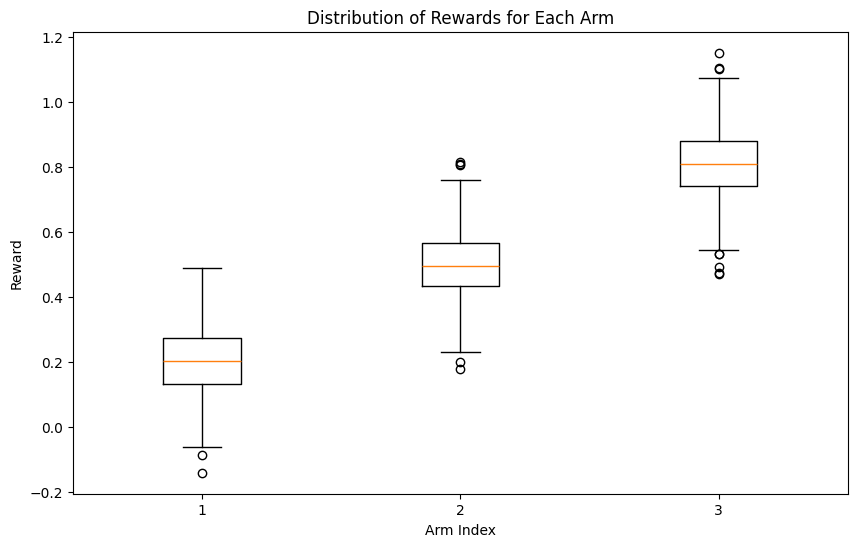

In [2]:
# Create a simple bandit with 3 arms
bandit = Bandit(
    arms=[0.2, 0.5, 0.8],
    sampling_type='gaussian',
    parameter=0.1
)

# Sample from each arm
samples = [bandit.pull(i, ntimes=1000) for i in range(3)]

# Plot distributions
plt.figure(figsize=(10, 6))
plt.boxplot(samples)
plt.title('Distribution of Rewards for Each Arm')
plt.xlabel('Arm Index')
plt.ylabel('Reward')
plt.show()

## Changepoint Bandit Class

The `CPBandit` class extends the basic bandit to handle changepoints in the reward distributions.

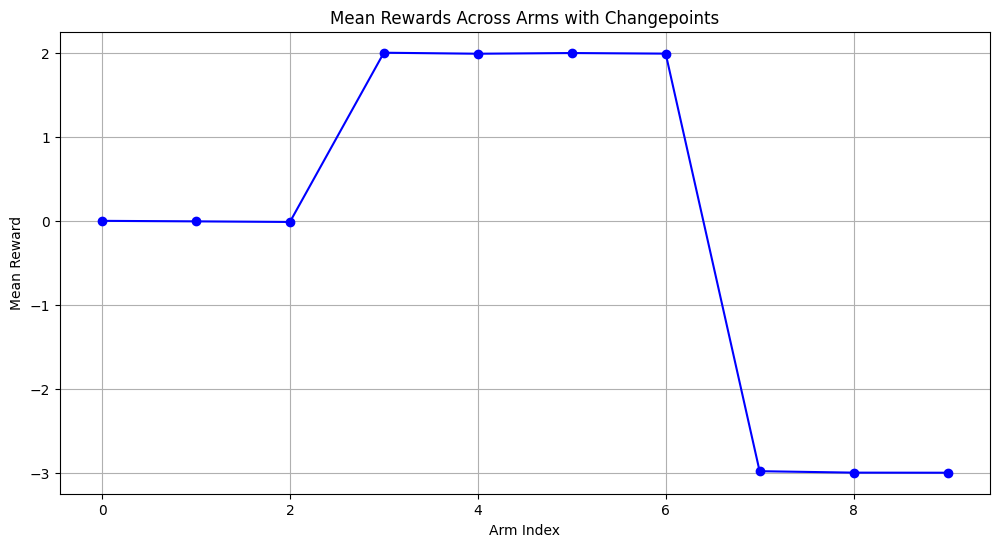

In [3]:
# Create a CPBandit with 3 sections
cp_bandit = CPBandit(
    sec_len=[3, 4, 3],
    sec_means=[0, 2, -3],
    sampling_type='gaussian',
    parameter=0.1
)

# Sample from all arms
n_arms = sum(cp_bandit.sec_len)
samples = [cp_bandit.pull(i, ntimes=100) for i in range(n_arms)]

# Plot means
means = [np.mean(s) for s in samples]
plt.figure(figsize=(12, 6))
plt.plot(means, 'bo-')
plt.title('Mean Rewards Across Arms with Changepoints')
plt.xlabel('Arm Index')
plt.ylabel('Mean Reward')
plt.grid(True)
plt.show()